# 二维无涨落正则模

JAM 和 Basilisk 采用 $64^2$ 周期网格、$L/h_0=128$、$\Delta t^*=8$ 和吸引系数 $a=0.0084375$。斜向 $(m_x,m_y)=(2,2)$ 正弦模态的初始振幅为 $10^{-3}h_0$。连续长波色散关系为

$$s(q)=q^2\left(\frac{1}{12\mu_g}+\frac{1}{4\mu_l |q|}\right)\left(3a-\frac{\gamma q^2}{2}\right).$$

本例用 $\gamma=\mu_l=h_0=1$、$\mu_g=0.02$。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

root = Path.cwd()
if not (root / "data").is_dir():
    root = root / "postprocess"
sys.path.insert(0, str(root))
from plot_style import setup
setup()

with np.load(root / "data" / "normal_mode_2d.npz") as source:
    data = {name: source[name] for name in source.files}
time = data["time"]
length = float(data["length"])
q = 2*np.pi*np.linalg.norm(data["mode"])/length
rate = q**2*(1/.24+1/(4*q))*(3*float(data["attraction"])-.5*q*q)
amplitude = [data["jam_amplitude"], data["basilisk_amplitude"]]
fits = [np.polyfit(time, np.log(a/a[0]), 1)[0] for a in amplitude]
assert rate > 0 and np.allclose(fits, rate, rtol=.003)
print(f"JAM {fits[0]:.8e}; Basilisk {fits[1]:.8e}; continuum {rate:.8e}")


JAM 1.80082940e-03; Basilisk 1.80082940e-03; continuum 1.80299030e-03


## 二维厚度场与模态增长

左图为 Basilisk 保存的末态。右图为两套求解器的模态振幅和连续理论。

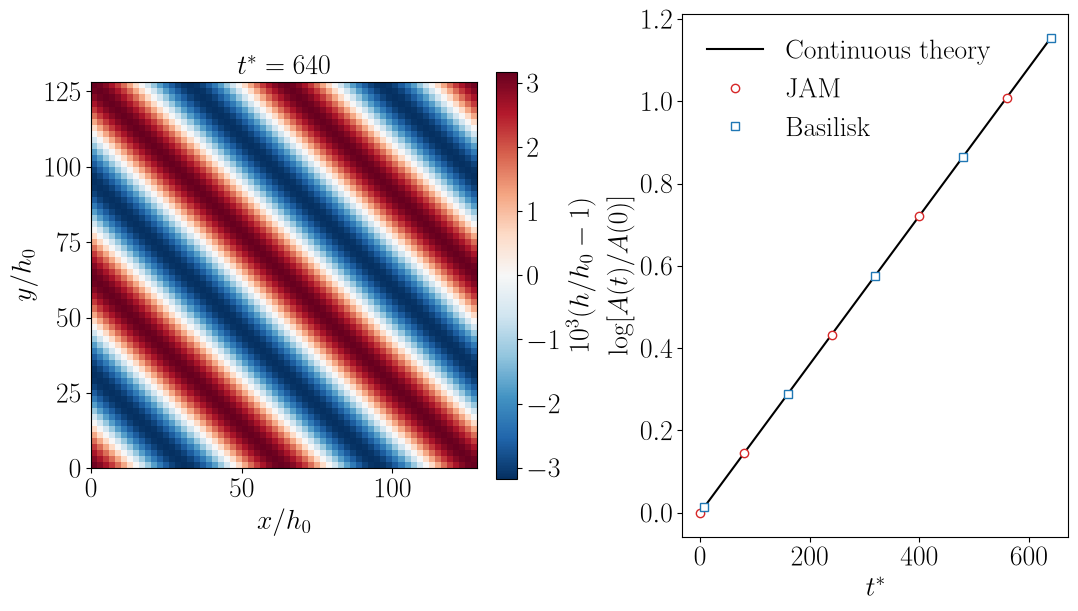

In [2]:

fig, (field_ax, rate_ax) = plt.subplots(1, 2, figsize=(32/3, 6), layout="constrained")
field = 1e3*(data["basilisk_final"].T-1)
bound = float(np.max(abs(field)))
im = field_ax.imshow(field, extent=(0,length,0,length), origin="lower",
                     cmap="RdBu_r", vmin=-bound, vmax=bound, interpolation="nearest")
fig.colorbar(im, ax=field_ax, shrink=.78, label=r"$10^3(h/h_0-1)$")
field_ax.set(xlabel=r"$x/h_0$", ylabel=r"$y/h_0$", title=rf"$t^*={time[-1]:g}$")
rate_ax.plot(time, rate*time, "k-", label="Continuous theory")
for a, color, marker, start, label in zip(
        amplitude, ("#D62728", "#1F77B4"), ("o", "s"), (0, 1), ("JAM", "Basilisk")):
    rate_ax.plot(time[start::2], np.log(a/a[0])[start::2], marker, color=color,
                 markerfacecolor="white", label=label)
rate_ax.set(xlabel=r"$t^*$", ylabel=r"$\log[A(t)/A(0)]$")
rate_ax.legend(loc="upper left")
for ax in (field_ax, rate_ax):
    ax.grid(False, which="both")
fig.savefig(root / "figures" / "normal_mode_2d.png", dpi=600)
fig.savefig(root / "figures" / "normal_mode_2d.pdf")
plt.show()


连续理论与拟合增长率相差约 0.12%。这是接触前的小扰动失稳算例。